<a href="https://colab.research.google.com/github/Ijlal40/Ijlal40.github.io/blob/master/DigitRecognition_LSTM_Optimizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#installing mnist database
from keras.datasets import mnist

from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import matplotlib.pyplot as plt

from keras.utils import to_categorical
from keras.models import Sequential, Model

#Fixing the random seed for reproducibility purposes
static_seed = 2
np.random.seed(static_seed)

# labels to help represent each digit during the visualisation portion
digit_labels = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

(X_train, y_train), (X_test, y_test) = mnist.load_data() #loading and splitting data respetively via MNIST functions

#Normalizing the data
X_train = X_train / 255.0
X_test = X_test / 255.0

#One-hot encoding
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

11490434/11490434 [==============================] - 2s 0us/step


##Changing Optimizer
In order to increase the val_accuracy, I will try different optimizers and compare them to one another.

In [ ]:
#model 1 has optimzied epochs and uses various optimizers
model1 = keras.Sequential()
model1.add(layers.LSTM(10, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
model1.add(layers.LSTM(10))
model1.add(layers.Dense(10, activation='softmax'))
print(model1.summary())
model1.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 28, 10)            1560      
                                                                 
 lstm_1 (LSTM)               (None, 10)                840       
                                                                 
 dense (Dense)               (None, 10)                110       
                                                                 
Total params: 2510 (9.80 KB)
Trainable params: 2510 (9.80 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
None


In [ ]:
LSTM_model1 = model1.fit(X_train, y_train, validation_split=0.2, batch_size=128, epochs=10)

Epoch 1/10
375/375 [==============================] - 12s 11ms/step - loss: 1.6833 - accuracy: 0.4330 - val_loss: 1.1604 - val_accuracy: 0.6513
Epoch 2/10
375/375 [==============================] - 3s 8ms/step - loss: 0.9269 - accuracy: 0.7306 - val_loss: 0.7006 - val_accuracy: 0.8020
Epoch 3/10
375/375 [==============================] - 3s 9ms/step - loss: 0.6329 - accuracy: 0.8202 - val_loss: 0.5428 - val_accuracy: 0.8461
Epoch 4/10
375/375 [==============================] - 4s 10ms/step - loss: 0.4998 - accuracy: 0.8587 - val_loss: 0.4336 - val_accuracy: 0.8795
Epoch 5/10
375/375 [==============================] - 3s 9ms/step - loss: 0.4270 - accuracy: 0.8792 - val_loss: 0.3833 - val_accuracy: 0.8919
Epoch 6/10
375/375 [==============================] - 3s 9ms/step - loss: 0.3766 - accuracy: 0.8926 - val_loss: 0.3388 - val_accuracy: 0.9049
Epoch 7/10
375/375 [==============================] - 4s 11ms/step - loss: 0.3435 - accuracy: 0.9007 - val_loss: 0.3110 - val_accuracy: 0.9126
Ep

Results for various optimizers (previous data stored here as images)

Using RMSprop
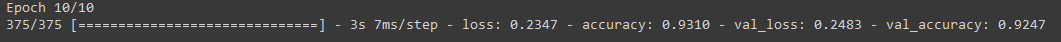

Using Ftrl
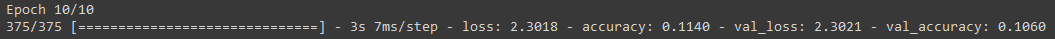

Using SGD
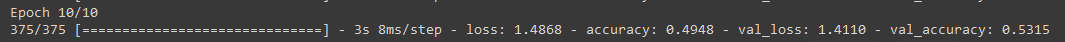

Using Adamax
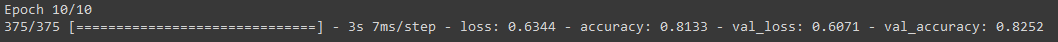

Using Adam
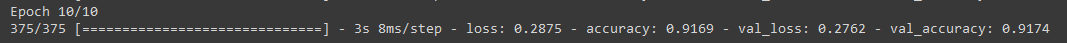

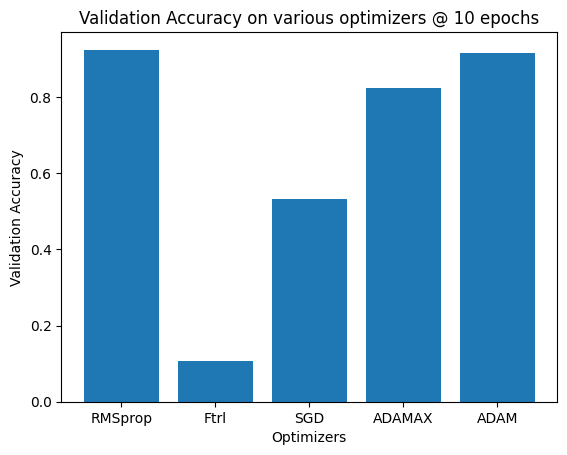

In [ ]:
x_axis_optimizers = ['RMSprop', 'Ftrl', 'SGD', 'ADAMAX', 'ADAM']
y_axis_optimizers = [0.9247, 0.1060, 0.5315, 0.8252, 0.9174]

plt.bar(x_axis_optimizers, y_axis_optimizers)
plt.title('Validation Accuracy on various optimizers @ 10 epochs')
plt.xlabel('Optimizers')
plt.ylabel('Validation Accuracy')
plt.show()

When comparing the validation accuracies between various available optimizers in the keras library. We can see that when it comes to digit recognition, both ADAM and RMSprop are very close to one another, no other optimizer tested came close. Therefore, since ADAM was slightly higher accuracy wise, we will be using it as our main optimizer for further optimizations.

##Adjusting Batch Sizes

In [ ]:
#model 2 has uses adam as its main optimizer
model2 = keras.Sequential()
model2.add(layers.LSTM(10, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
model2.add(layers.LSTM(10))
model2.add(layers.Dense(10, activation='softmax'))
print(model2.summary())
model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_2 (LSTM)               (None, 28, 10)            1560      
                                                                 
 lstm_3 (LSTM)               (None, 10)                840       
                                                                 
 dense_1 (Dense)             (None, 10)                110       
                                                                 
Total params: 2510 (9.80 KB)
Trainable params: 2510 (9.80 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
None


In [ ]:
LSTM_model2 = model2.fit(X_train, y_train, validation_split=0.2, batch_size=512, epochs=10)

Epoch 1/10
94/94 [==============================] - 6s 22ms/step - loss: 2.1866 - accuracy: 0.2022 - val_loss: 1.9689 - val_accuracy: 0.3314
Epoch 2/10
94/94 [==============================] - 1s 14ms/step - loss: 1.6569 - accuracy: 0.4737 - val_loss: 1.3560 - val_accuracy: 0.5838
Epoch 3/10
94/94 [==============================] - 1s 12ms/step - loss: 1.1842 - accuracy: 0.6389 - val_loss: 1.0231 - val_accuracy: 0.6842
Epoch 4/10
94/94 [==============================] - 1s 10ms/step - loss: 0.9466 - accuracy: 0.7040 - val_loss: 0.8451 - val_accuracy: 0.7412
Epoch 5/10
94/94 [==============================] - 1s 10ms/step - loss: 0.8053 - accuracy: 0.7514 - val_loss: 0.7288 - val_accuracy: 0.7793
Epoch 6/10
94/94 [==============================] - 1s 11ms/step - loss: 0.7042 - accuracy: 0.7864 - val_loss: 0.6471 - val_accuracy: 0.8079
Epoch 7/10
94/94 [==============================] - 1s 10ms/step - loss: 0.6263 - accuracy: 0.8156 - val_loss: 0.5711 - val_accuracy: 0.8395
Epoch 8/10
94

Batch Sizes Tested: 16, 32, 64, 128, 256, 512


---

@ 16, val_accuracy = 95.62%, total runtime = 219s
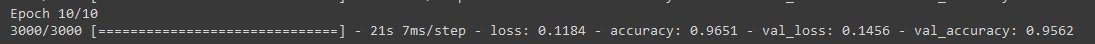

---

@ 32, val_accuracy = 95.63%, total runtime = 116s
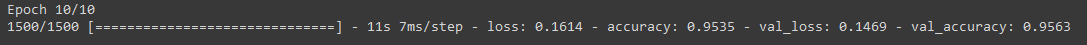

---
@ 64, val_accuracy = 94.40%, total runtime = 59s
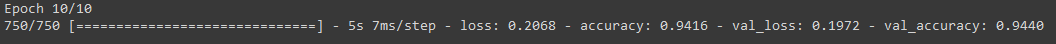

---
@ 128, val_accuracy = 92.98%, total runtime = 34s
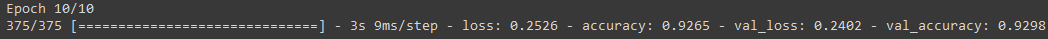

---
@ 256, val_accuracy = 91.58%, total runtime = 20s
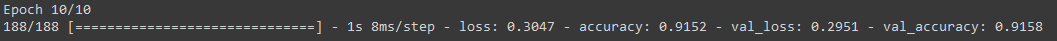

---
@ 512, val_accuracy = 87.96%, total runtime = 14s
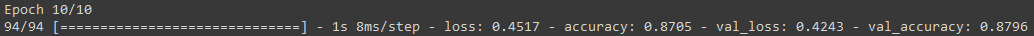


Visualization of Batch Size Results

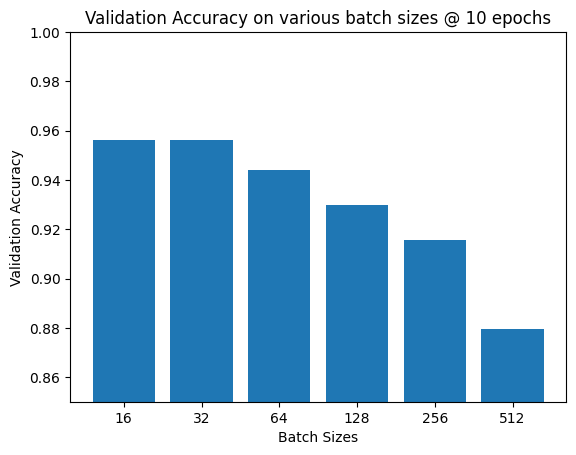

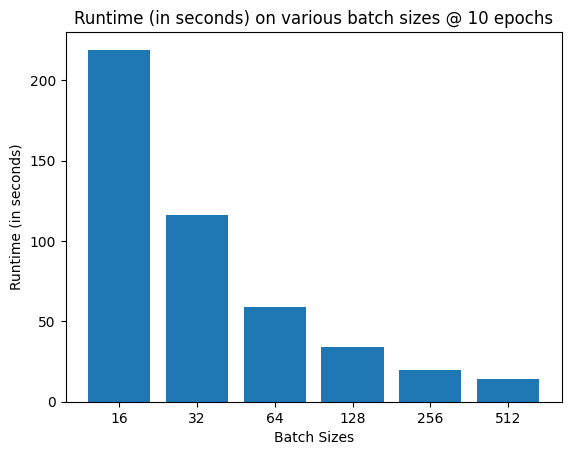

In [ ]:
x_axis_batchsizes = ['16', '32', '64', '128', '256', '512']
y_axis_batch_acc = [0.9562, 0.9563, 0.9440, 0.9298, 0.9158, 0.8796]
y_axis_batch_runtimes = [219, 116, 59, 34, 20, 14]

plt.ylim(0.85, 1.00)
plt.bar(x_axis_batchsizes, y_axis_batch_acc)
plt.title('Validation Accuracy on various batch sizes @ 10 epochs')
plt.xlabel('Batch Sizes')
plt.ylabel('Validation Accuracy')
plt.show()

print("\n")

plt.bar(x_axis_batchsizes, y_axis_batch_runtimes)
plt.title('Runtime (in seconds) on various batch sizes @ 10 epochs')
plt.xlabel('Batch Sizes')
plt.ylabel('Runtime (in seconds)')
plt.show()



As a result of the testing done in regards to batch size, it seems like a batch size of 64 is a perfect medium between speed and validation accuracy. Therefore, we will be choosing to use 64 as our batch size for future optimizations.

##Adjusting hidden layers

In [ ]:
#model 3 uses adam as its main optimizer and has a batch size of 64
model3 = keras.Sequential()
model3.add(layers.LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
model3.add(layers.LSTM(64))
model3.add(layers.Dense(10, activation='softmax'))
print(model3.summary())
model3.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_4 (LSTM)               (None, 28, 64)            23808     
                                                                 
 lstm_5 (LSTM)               (None, 64)                33024     
                                                                 
 dense_2 (Dense)             (None, 10)                650       
                                                                 
Total params: 57482 (224.54 KB)
Trainable params: 57482 (224.54 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
None


In [ ]:
LSTM_model3 = model3.fit(X_train, y_train, validation_split=0.2, batch_size=64, epochs=10)

Epoch 1/10
750/750 [==============================] - 11s 10ms/step - loss: 0.5065 - accuracy: 0.8381 - val_loss: 0.1909 - val_accuracy: 0.9442
Epoch 2/10
750/750 [==============================] - 7s 9ms/step - loss: 0.1545 - accuracy: 0.9536 - val_loss: 0.1165 - val_accuracy: 0.9643
Epoch 3/10
750/750 [==============================] - 6s 9ms/step - loss: 0.1065 - accuracy: 0.9677 - val_loss: 0.0922 - val_accuracy: 0.9729
Epoch 4/10
750/750 [==============================] - 7s 9ms/step - loss: 0.0824 - accuracy: 0.9756 - val_loss: 0.0833 - val_accuracy: 0.9743
Epoch 5/10
750/750 [==============================] - 6s 8ms/step - loss: 0.0682 - accuracy: 0.9793 - val_loss: 0.0708 - val_accuracy: 0.9783
Epoch 6/10
750/750 [==============================] - 7s 9ms/step - loss: 0.0578 - accuracy: 0.9825 - val_loss: 0.0783 - val_accuracy: 0.9778
Epoch 7/10
750/750 [==============================] - 6s 9ms/step - loss: 0.0479 - accuracy: 0.9851 - val_loss: 0.0598 - val_accuracy: 0.9806
Epoc

Tested combinations (first x second layer): 5x5, 10x10, 16x16, 16x32, 32x32, 32x64, 64x64


---

5x5, val accuracy = 84.85%, total runtime = 60s
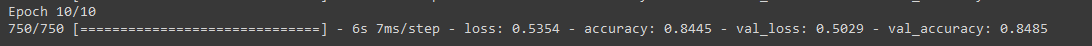

---

10x10, val accuracy = 93.57%, total runtime = 58s
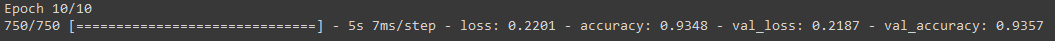

---

16x16, val accuracy = 96.01%, total runtime = 58s
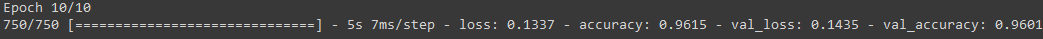

---

16x32, val accuracy = 97.41%, total runtime = 58s
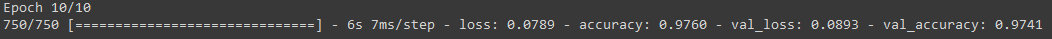

---

32x32, val accuracy = 98.08%, total runtime = 61s
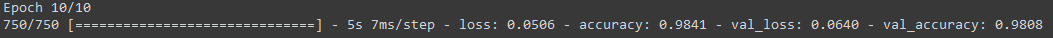

---

32x64, val accuracy = 97.98%, total runtime = 59s
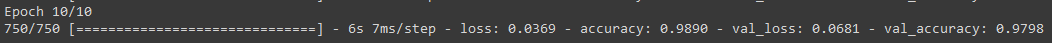

---

64x64, val accuracy = 97.77%, total runtime = 59s
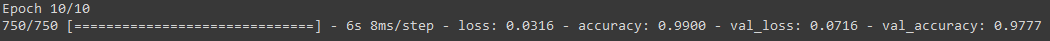

Visualization of Hidden Layer Unit Results

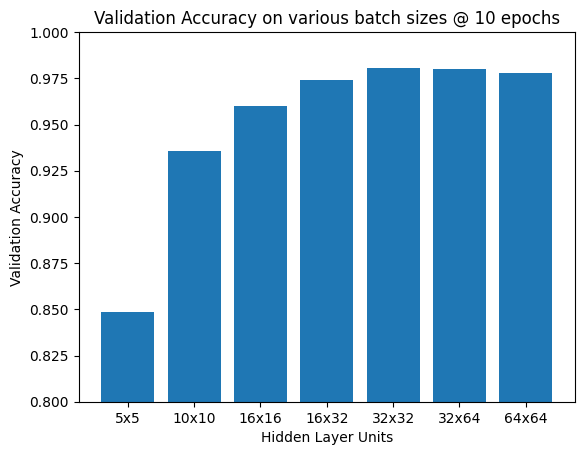

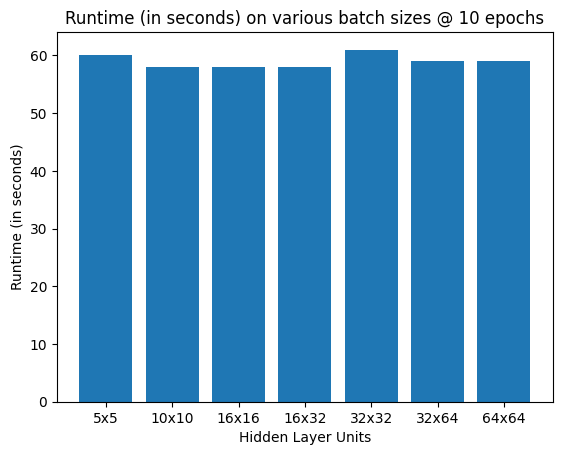

In [ ]:
x_axis_hiddenunits = ['5x5', '10x10', '16x16', '16x32', '32x32', '32x64', '64x64']
y_axis_hiddenunits_acc = [0.8485, 0.9357, 0.9601, 0.9741, 0.9808, 0.9798, 0.9777]
y_axis_hiddenunits_runtimes = [60, 58, 58, 58, 61, 59, 59]

plt.ylim(0.80, 1.00)
plt.bar(x_axis_hiddenunits, y_axis_hiddenunits_acc)
plt.title('Validation Accuracy on various batch sizes @ 10 epochs')
plt.xlabel('Hidden Layer Units')
plt.ylabel('Validation Accuracy')
plt.show()

print("\n")

plt.bar(x_axis_hiddenunits, y_axis_hiddenunits_runtimes)
plt.title('Runtime (in seconds) on various batch sizes @ 10 epochs')
plt.xlabel('Hidden Layer Units')
plt.ylabel('Runtime (in seconds)')
plt.show()

From testing various combinations of units in both hidden layers, it is evident that runtime is not too different from one another and we can solely look at the validation accuracy for this one, and it seems like 32x32 offers the highest validation accuracy, therefore it will be the standard for future optimizations.


##Epoch Optimization

In [ ]:
#model 4 uses adam as its main optimizer, has a batch size of 64, and has 32 units in both the first and second hidden layer
model4 = keras.Sequential()
model4.add(layers.LSTM(32, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
model4.add(layers.LSTM(32))
model4.add(layers.Dense(10, activation='softmax'))
print(model4.summary())
model4.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_6 (LSTM)               (None, 28, 32)            7808      
                                                                 
 lstm_7 (LSTM)               (None, 32)                8320      
                                                                 
 dense_3 (Dense)             (None, 10)                330       
                                                                 
Total params: 16458 (64.29 KB)
Trainable params: 16458 (64.29 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
None


In [ ]:
LSTM_model4 = model4.fit(X_train, y_train, validation_split=0.2, batch_size=64, epochs=50)

Epoch 1/50
750/750 [==============================] - 12s 11ms/step - loss: 0.7368 - accuracy: 0.7641 - val_loss: 0.2852 - val_accuracy: 0.9151
Epoch 2/50
750/750 [==============================] - 7s 9ms/step - loss: 0.2369 - accuracy: 0.9296 - val_loss: 0.1755 - val_accuracy: 0.9480
Epoch 3/50
750/750 [==============================] - 7s 9ms/step - loss: 0.1584 - accuracy: 0.9535 - val_loss: 0.1374 - val_accuracy: 0.9597
Epoch 4/50
750/750 [==============================] - 6s 8ms/step - loss: 0.1246 - accuracy: 0.9633 - val_loss: 0.1178 - val_accuracy: 0.9638
Epoch 5/50
750/750 [==============================] - 7s 9ms/step - loss: 0.1035 - accuracy: 0.9696 - val_loss: 0.1050 - val_accuracy: 0.9686
Epoch 6/50
750/750 [==============================] - 7s 9ms/step - loss: 0.0884 - accuracy: 0.9732 - val_loss: 0.0871 - val_accuracy: 0.9733
Epoch 7/50
750/750 [==============================] - 7s 9ms/step - loss: 0.0752 - accuracy: 0.9777 - val_loss: 0.1003 - val_accuracy: 0.9690
Epoc

In [ ]:
plt.figure(figsize = (25,12))
plt.subplot(121)
plt.plot(LSTM_model4.history['loss'])
plt.plot(LSTM_model4.history['val_loss'])
plt.title('model loss', fontsize = 18, fontweight = "bold")
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','validation'], loc='upper right', prop={'size':20})

plt.subplot(122)
plt.plot(LSTM_model4.history['accuracy'])
plt.plot(LSTM_model4.history['val_accuracy'])
plt.title('model accuracy', fontsize = 18, fontweight="bold")
plt.ylabel('acc')
plt.xlabel('epochs')
plt.legend(['train','validation'],loc='lower right',prop={'size':20})



As shown in the graphs above, you can see that after epoch x, the validation_loss starts to fluctuate and the validation_accuracy slowly increases (sometimes it even decreases), this is most likely due to the model overfitting the training data. Therefore, for optimization purposes (to reduce both overfitting and runtime) we will set the epochs for our model to 20.

val_accuracy @ epoch 20 = 98.62%
